# 08 · Which representation retains the distinction?

The same configuration is represented in three ways: one whole-image vector, a collection of 8 × 8 patch vectors, and a field of two-dimensional gradients. We use inspectable fixed representations. Each pattern rearranges 32 copies of one motif and 32 of its transpose on an 8 × 8 patch grid.

## Setup
Stage 2 holds the motif inventory fixed and changes spatial organization.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.fft import dctn
from observables.core import moments,relative_distance
from observables.images import tiled_orientation
from observables.spatial import *
OUT=ROOT/'results'/'stage2'
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.figsize':(8,3.8),'figure.dpi':110,
 'figure.constrained_layout.use':True,'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
images={name:mosaic(name) for name in LAYOUTS}
gallery=[representations(image) for image in images.values()]

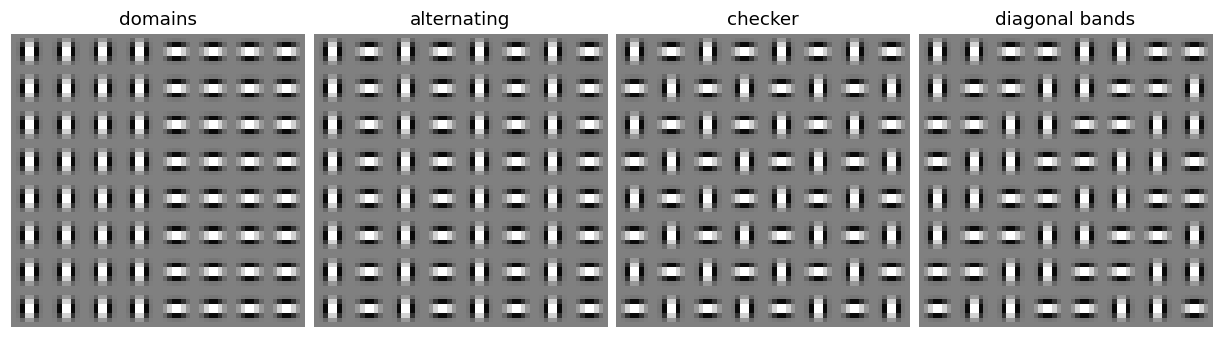

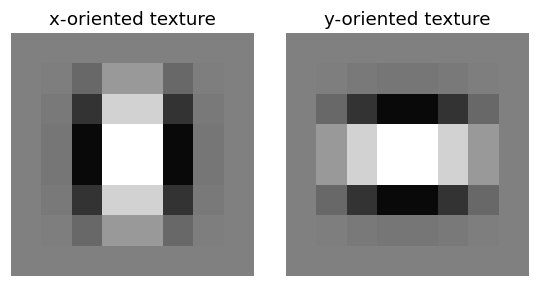

In [3]:
fig,axes=plt.subplots(1,4,figsize=(11,3))
for ax,(name,a) in zip(axes,images.items()):
    ax.imshow(a,cmap='gray',vmin=-np.max(np.abs(tiles())),vmax=np.max(np.abs(tiles())));ax.set_title(name);ax.axis('off')
show('08_mosaics')
fig,axes=plt.subplots(1,2,figsize=(5,2.5))
for ax,a,title in zip(axes,tiles(),['x-oriented texture','y-oriented texture']):
    ax.imshow(a,cmap='gray',vmin=-np.max(np.abs(tiles())),vmax=np.max(np.abs(tiles())));ax.set_title(title);ax.axis('off')
show('08_motifs')

## An exact permutation control
The motifs have zero-valued borders. Periodic central differences therefore see the same local gradient inventory in every rearrangement. Each aligned patch appears with identical multiplicity. All permutation-invariant moments of aligned patch vectors agree exactly. Patch mean and Q are two finite demonstrations of the stronger multiset identity.

In [5]:
ref=gallery[0]
rows=[]
for name,g in zip(LAYOUTS,gallery):
    rows.append((name,*[relative_distance(ref[k],g[k]) for k in ['pixels','patch_mean','patch_Q','global_Q','local_Q_8','correlation']]))
frame=pd.DataFrame(rows,columns=['arrangement','whole pixels','patch mean','patch Q','global gradient Q','local Q grid8','Q correlation'])
display(frame.round(6));frame.to_csv(OUT/'representation_collisions.csv',index=False)
for a in images.values():
    assert sorted(map(tuple,patches(a)))==sorted(map(tuple,patches(images[LAYOUTS[0]])))
assert np.max(frame[['patch mean','patch Q','global gradient Q']].to_numpy())<1e-10

,arrangement,whole pixels,patch mean,patch Q,global gradient Q,local Q grid8,Q correlation
0,domains,0.000000,0.0,0.0,0.0,0.000000,0.000000
1,alternating,0.485913,0.0,0.0,0.0,0.707107,0.708733
2,checker,0.485913,0.0,0.0,0.0,0.707107,0.759348
3,diagonal bands,0.485913,0.0,0.0,0.0,0.707107,0.713358


## A change of feature coordinates preserves these contractions
Apply the full orthonormal two-dimensional DCT to each patch. The Gram matrix of patch vectors remains unchanged. Hence pairwise cosines and norms of tensor-moment differences are unchanged. Truncating coefficients would introduce a different representation and a loss of information.

In [7]:
a=images['domains'];b=np.roll(images['checker'],3,axis=1)
def dct_patches(x):
    return dctn(patches(x).reshape(-1,8,8),axes=(1,2),norm='ortho').reshape(-1,64)
for image in [a,b]:
    x,y=patches(image),dct_patches(image)
    np.testing.assert_allclose(x@x.T,y@y.T,atol=1e-12)
raw=[moments(patches(x)) for x in [a,b]]
transformed=[moments(dct_patches(x)) for x in [a,b]]
display(pd.DataFrame({'observable':['patch mean','patch Q'],
 'raw distance':[relative_distance(raw[0][k],raw[1][k]) for k in [0,1]],
 'full DCT distance':[relative_distance(transformed[0][k],transformed[1][k]) for k in [0,1]]}).round(8))

,observable,raw distance,full DCT distance
0,patch mean,0.633701,0.633701
1,patch Q,0.697851,0.697851


## Whole-image Q
For one image vector x normalized to u, Q(u) is rank-one plus the isotropic subtraction. Its normalized contraction with Q(v) is $(d\cos^2\theta-1)/(d-1)$. The retrieval score $1-\cos^2\theta$ has the same ranking while avoiding a 4096 × 4096 matrix. It removes global contrast sign while retaining position sensitivity.

This experiment isolates representation and pooling. Learned encoders can be introduced later with the same configuration controls.